# Interpret pathway-guided programs in Pan-GI

Connect cellular populations to guided sparse elements and their aligned
Reactome pathways. This example follows the analyses in Figure 5.
All population summaries use curated annotations.

## 1. Load the programs

In [1]:
%matplotlib inline
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "tutorials/data").is_dir())
sys.path.insert(0, str(ROOT / "tutorials"))
from _common import (configure_plots, save_figure, clean_map, pretty,
                     expression_cmap, program_cmap, pathway_cmap, dot_atlas)

configure_plots()
DATA = ROOT / "tutorials/data"
OUTPUT = ROOT / "tutorials/outputs"

In [2]:
cells = pd.read_csv(DATA / "pangi_cells.csv.gz", dtype={"cell_id": str})
programs = pd.read_csv(DATA / "pangi_programs.csv")
display(programs.rename(columns={"feature_id": "SE index"}))
print(f"{len(cells):,} cells | {cells.cell_type.nunique()} populations")

,SE index,cell_type,pathway_name,pathway_label
0,88,Mature_B,REACTOME_ANTIGEN_ACTIVATES_B_CELL_RECEPTOR_BCR...,B-cell receptor signaling
1,507,Keratinocyte,REACTOME_FORMATION_OF_THE_CORNIFIED_ENVELOPE,Cornified envelope formation
2,1467,Smooth_muscle,REACTOME_SMOOTH_MUSCLE_CONTRACTION,Smooth muscle contraction
3,1692,B_plasma,REACTOME_UNFOLDED_PROTEIN_RESPONSE_UPR,Unfolded protein response


31,000 cells | 31 populations


## 2. Compare program and pathway activity

Left: mean positive post-Top-K program activation. Right: mean activity
of the aligned pathway. Each column is scaled to its maximum across the
12 displayed populations to compare localization, rather than absolute magnitudes.

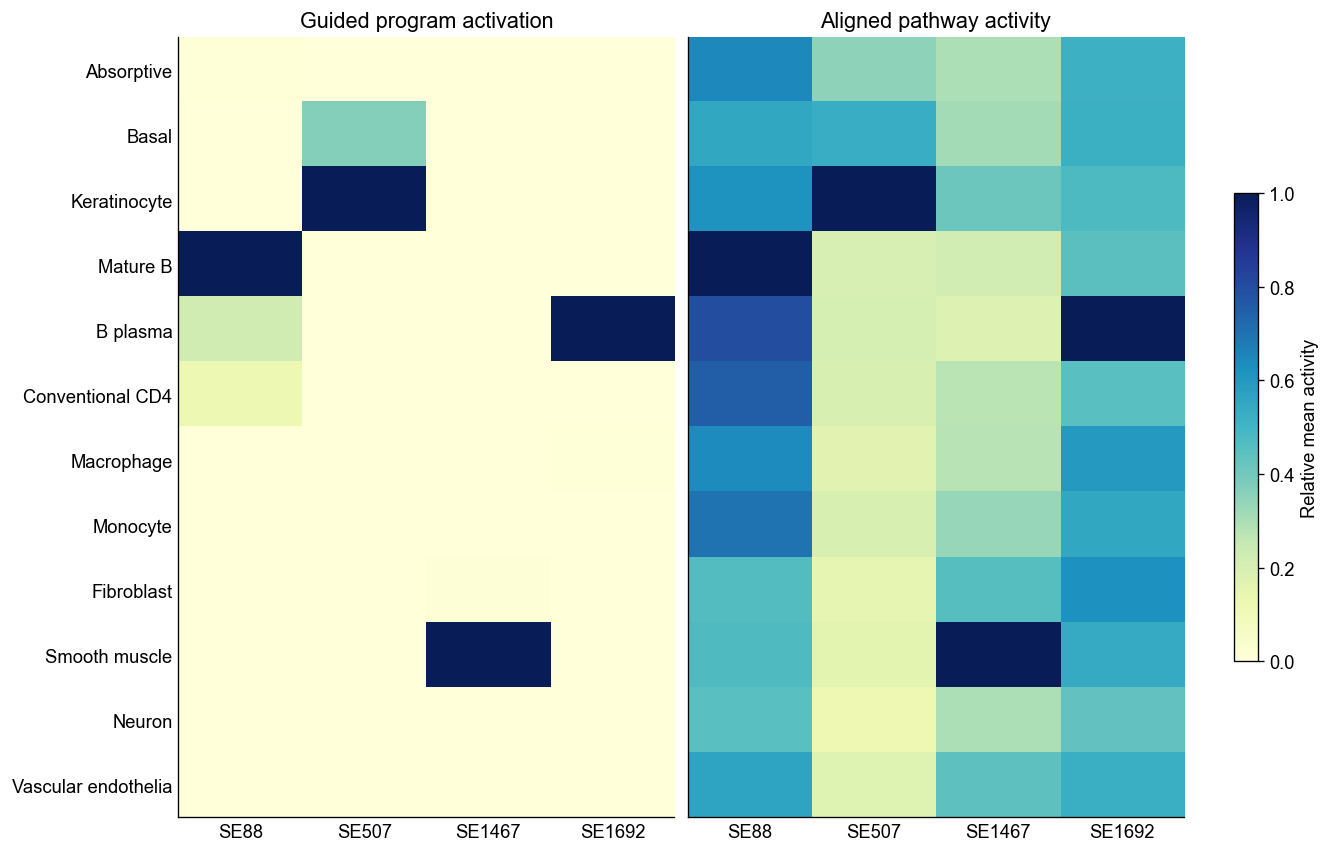

In [3]:
populations = ["Absorptive", "Basal", "Keratinocyte", "Mature_B", "B_plasma",
               "Conventional_CD4", "Macrophage", "Monocyte", "Fibroblast",
               "Smooth_muscle", "Neuron", "Vascular_endothelia"]
features = programs.feature_id.tolist()
means = cells.groupby("cell_type").mean(numeric_only=True).loc[populations]
activation = means[[f"sparse_SE{f}" for f in features]]
activity = means[[f"pathway_SE{f}" for f in features]]
activation = activation / activation.max().clip(lower=1e-8)
activity = activity / activity.max().clip(lower=1e-8)

fig, axes = plt.subplots(1, 2, figsize=(11, 7), sharey=True, layout="constrained")
for ax, values, title in zip(axes, [activation, activity],
        ["Guided program activation", "Aligned pathway activity"]):
    image = ax.imshow(values.to_numpy(), cmap="YlGnBu", vmin=0, vmax=1, aspect="auto")
    ax.set_xticks(range(len(features)), [f"SE{f}" for f in features])
    ax.set_yticks(range(len(populations)), [pretty(p) for p in populations])
    ax.set_title(title)
    ax.tick_params(length=0)
fig.colorbar(image, ax=axes, shrink=0.6, label="Relative mean activity")
save_figure(fig, OUTPUT, "pangi_program_pathway_means")
plt.show()

## 3. Inspect one program across populations

Choose an SE index from the table above. The left panel shows sparse
activations; the right panel shows the corresponding pathway scores,
min-max normalized over the full example collection.

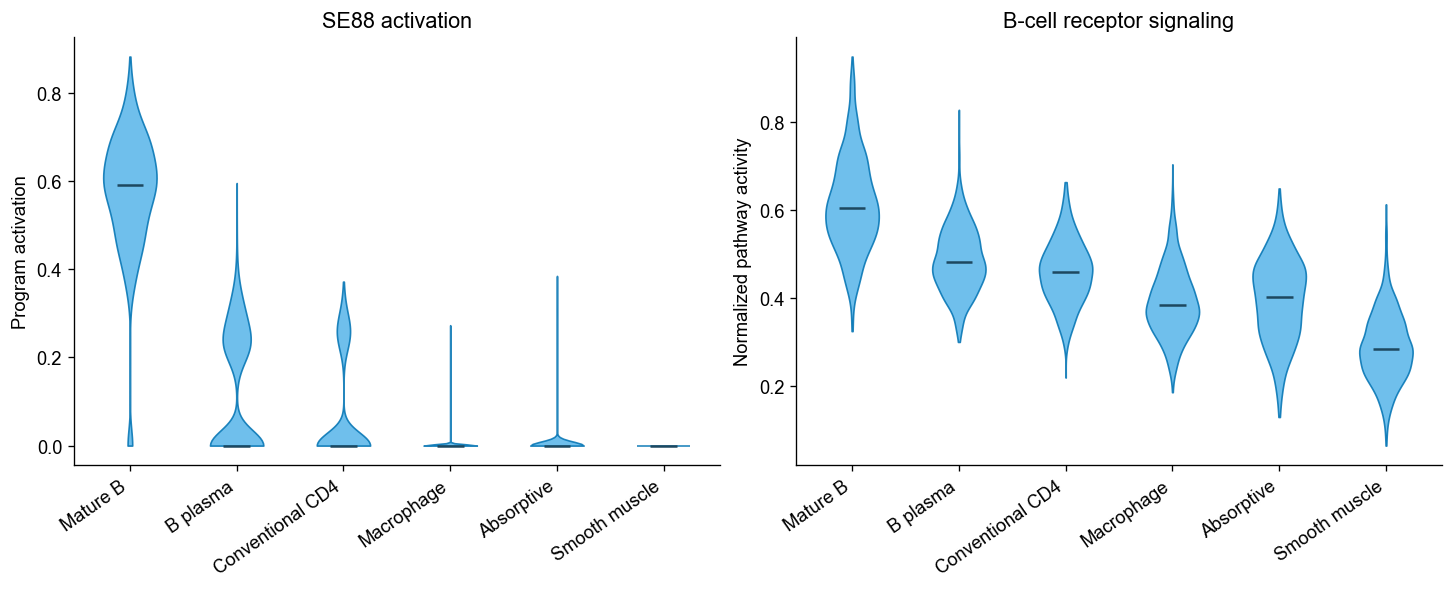

In [4]:
FEATURE_ID = 88
selected = ["Mature_B", "B_plasma", "Conventional_CD4", "Macrophage", "Absorptive", "Smooth_muscle"]
info = programs.set_index("feature_id").loc[FEATURE_ID]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")
for ax, column, title in zip(axes,
        [f"sparse_SE{FEATURE_ID}", f"pathway_SE{FEATURE_ID}"],
        [f"SE{FEATURE_ID} activation", info.pathway_label]):
    values = [cells.loc[cells.cell_type.eq(p), column].to_numpy() for p in selected]
    violin = ax.violinplot(values, positions=range(len(selected)), showextrema=False, showmedians=True)
    for body in violin["bodies"]:
        body.set_facecolor("#56B4E9")
        body.set_edgecolor("#0072B2")
        body.set_alpha(0.85)
    violin["cmedians"].set_color("#1d4860")
    ax.set_xticks(range(len(selected)), [pretty(p) for p in selected], rotation=35, ha="right")
    ax.set_ylabel("Program activation" if column.startswith("sparse") else "Normalized pathway activity")
    ax.set_title(title)
save_figure(fig, OUTPUT, "pangi_program_pathway_distributions")
plt.show()

The B-cell receptor program and its aligned pathway are concentrated
in the B-cell compartment. Pathway alignment is a training objective;
this concordance describes the learned representation, rather than an
independent test of biological causality.

## 4. Build a population-pathway atlas

Select one representative pathway per displayed population by its
activity relative to the other populations. Color shows scaled mean
activity; dot area shows the fraction of cells with a positive pathway
score. Full pathway names and both legends are retained.

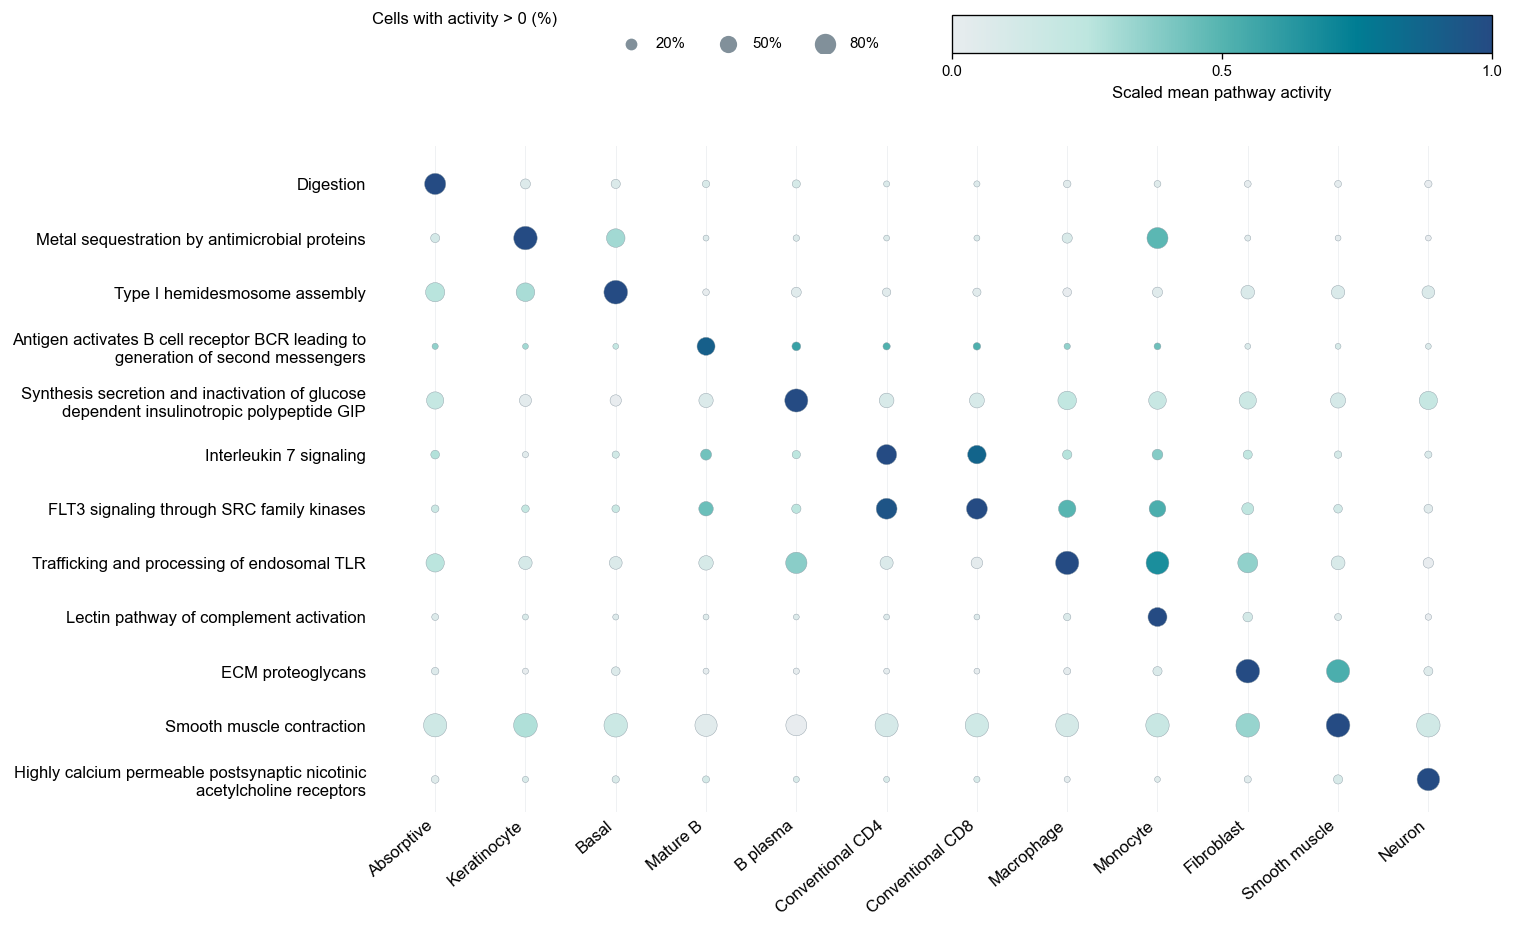

In [5]:
atlas = pd.read_csv(DATA / "pangi_pathway_atlas.csv.gz")
from _common import pathway_label
selected_populations = ["Absorptive", "Keratinocyte", "Basal", "Mature_B", "B_plasma",
                        "Conventional_CD4", "Conventional_CD8", "Macrophage", "Monocyte",
                        "Fibroblast", "Smooth_muscle", "Neuron"]
means = atlas.pivot(index="reactome_pathway", columns="cell_type", values="scaled_mean_pathway_activity")
fractions = atlas.pivot(index="reactome_pathway", columns="cell_type", values="fraction_active")
selected_pathways = []
for population in selected_populations:
    specificity = means[population] - means.drop(columns=population).mean(axis=1)
    pathway = next(p for p in specificity.sort_values(ascending=False).index if p not in selected_pathways)
    selected_pathways.append(pathway)
values = means.loc[selected_pathways, selected_populations].copy()
fraction = fractions.loc[selected_pathways, selected_populations].copy()
labels = [pathway_label(p) for p in selected_pathways]
values.index = labels
fraction.index = labels
fig, ax = dot_atlas(values, fraction, "Scaled mean pathway activity")
save_figure(fig, OUTPUT, "pangi_pathway_dot_atlas")
plt.show()